# 大模型微调 11：ChatGLM + LoRA 新媒体评论分类与信息抽取

本篇整理 `11-课件/新媒体行业评论智能分类与信息抽取系统.pptx` 和 `11-代码/ptune_chatglm`。项目把两类指令数据放在同一套 ChatGLM-6B 微调流程中：一类完成新媒体评论分类，另一类从自然语言中抽取 SPO 三元组。

## 学习目标

- 理解文本分类和信息抽取如何统一成“指令 + 输入 + 答案”的生成任务；
- 理解 ChatGLM-6B 的加载、输入构造和 label mask；
- 读懂 LoRA 配置、混合精度、梯度检查点和 checkpoint 保存；
- 能区分代码中默认启用的 LoRA 与可选但默认关闭的 P-Tuning；
- 能根据 JSONL 数据、训练参数和推理代码排查复现问题。

课程只提供 PPTX 和代码，没有单独 PDF 讲义。本篇以课件的章节顺序为主，以本地源码的实际行为为准。代码中的路径是作者机器路径，复现时必须替换。

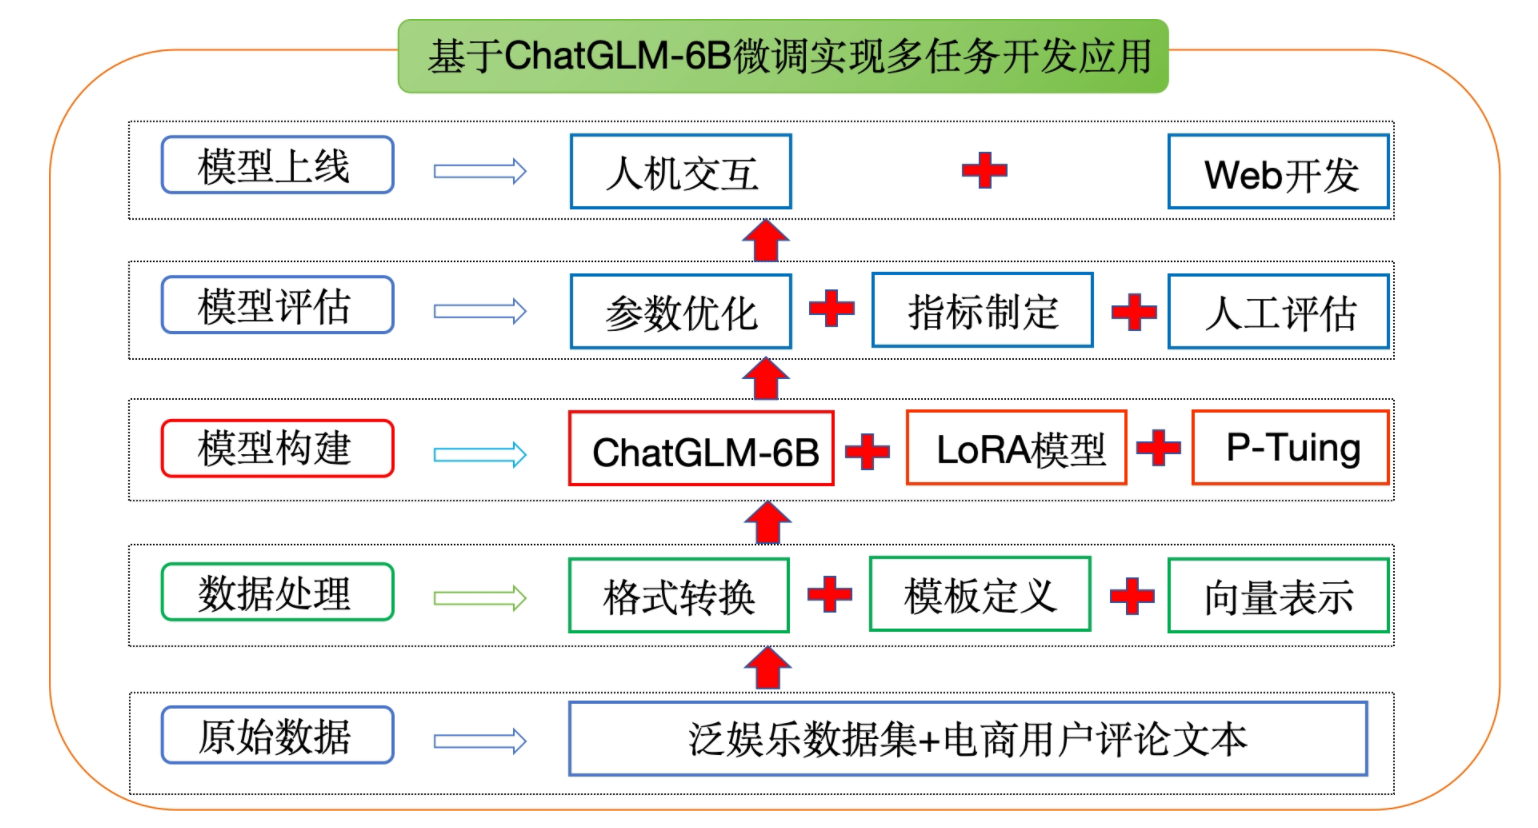

## 一、项目背景：分类和信息抽取

文本分类把一段文本按照内容或主题划分到类别，例如新闻、简历、邮件和办公文档分类。信息抽取则从无结构或半结构化文本中识别实体、关系和事件，并以结构化结果保存。

例如：

```text
小明和小秦是很好的朋友，他们都属于云南人，小明住在大理，小秦住在丽江。
```

可以抽取为：

```text
<小明，朋友，小秦>
<小明，住在，大理>
<小秦，住在，丽江>
```

项目以新媒体行业评论为背景，希望从海量评论和文章中同时得到类别与结构化关系，帮助平台管理信息、分析用户反馈和支持决策。

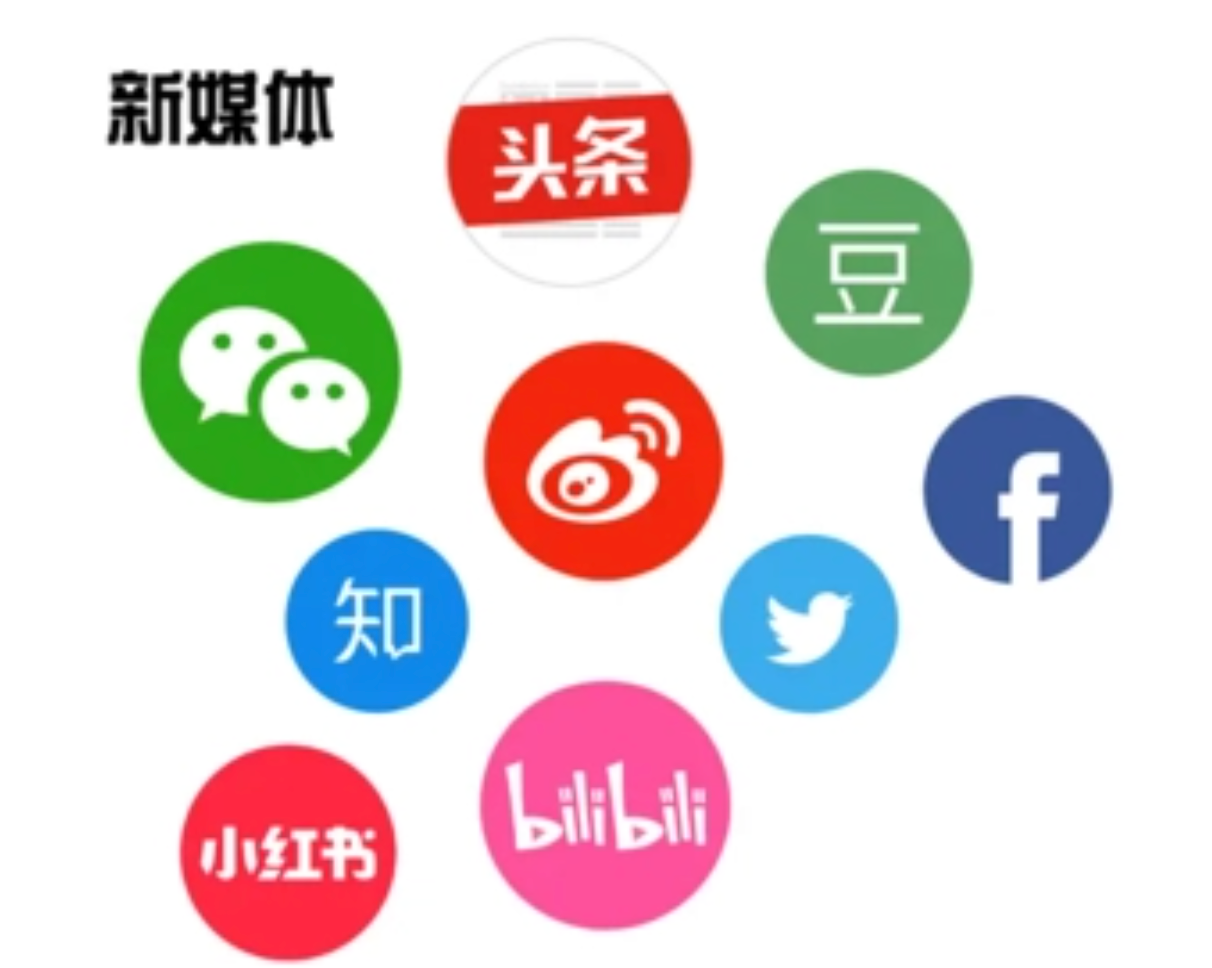

## 二、技术选型：ChatGLM-6B 与参数高效微调

课件选择 ChatGLM-6B + LoRA 完成联合任务。ChatGLM-6B 是支持中英文的对话语言模型，采用 GLM 架构，课件记录约 62 亿参数。课件回顾了它的结构改动：embedding 层梯度缩减、基于 DeepNorm 的 post LayerNorm、GeGLU 激活函数，以及 RoPE 旋转位置编码。

模型本身不需要在项目中重新定义，代码通过 `AutoTokenizer`、`AutoConfig` 和 `AutoModel` 加载远程模型实现。

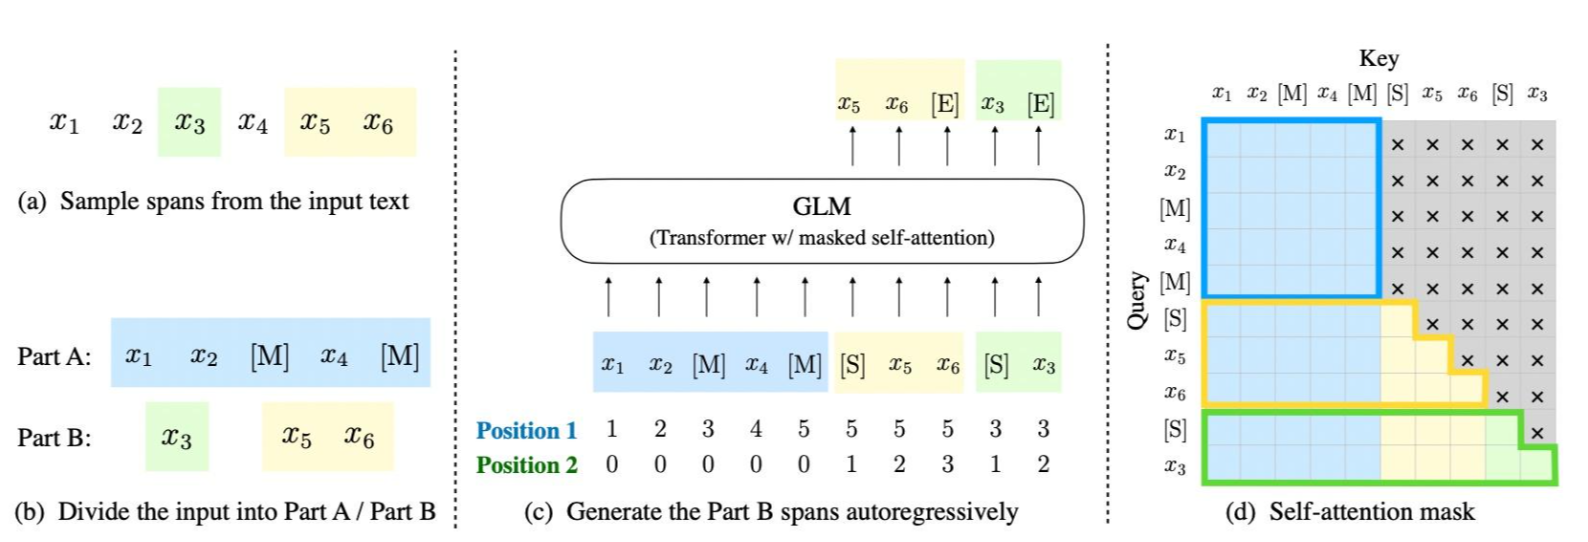

### 2.1 LoRA 原理

LoRA 冻结预训练模型的原始权重，在 Transformer 的 Linear 层旁边增加低秩旁支：

```text
原始权重 W：d × d
输入 x：    d
旁支 A：    d × r，把 d 降到 r
旁支 B：    r × d，把 r 升回 d
输出增量：  B(A(x))
```

其中 `r` 是秩，B 通常从零初始化。训练主要更新 A、B，减少显存和可训练参数；部署时可以把旁支与原权重合并。

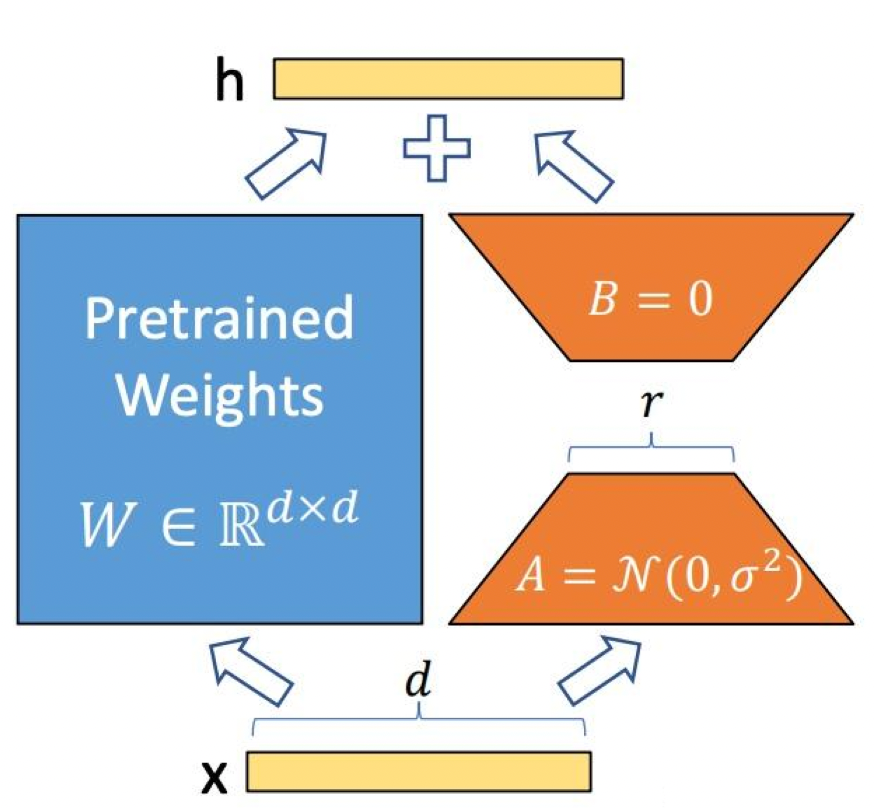

### 2.2 代码的真实微调模式

`glm_config.py` 中：

```python
self.use_lora = True
self.use_ptuning = False
```

所以下载版默认执行 LoRA，而不是 P-Tuning。`use_ptuning=True` 时，代码才会设置 `config.pre_seq_len` 和 `config.prefix_projection`，让 ChatGLM 使用 prefix encoder。笔记标题保留课件项目的 P-Tuning 命名，但实现分析以默认 LoRA 分支为准。

## 三、环境与工程结构

课件记录的训练环境是趋动云 CentOS 7、8 核 CPU、48 GB 内存、A800 80 GB、Python 3.9、PyTorch 1.11.0、CUDA 11.3.1。依赖包括：

```text
protobuf>=3.19.5,<3.20.1
transformers>=4.27.1
icetk
cpm_kernels
streamlit==1.17.0
matplotlib
datasets==2.10.1
accelerate==0.17.1
packaging>=20.0
psutil
pyyaml
peft
```

课件给出的步骤是创建 Python 3.9 环境、激活环境，再安装 `requirements.txt`。本地笔记只记录课程命令，不在当前电脑安装或启动训练。

| 路径 | 作用 |
| --- | --- |
| `glm_config.py` | 设备、模型、数据、LoRA/P-Tuning 和训练参数 |
| `data/` | JSONL 训练/验证数据和小样本示例 |
| `data_handle/data_preprocess.py` | JSONL 到 input/label 数组 |
| `data_handle/data_loader.py` | `load_dataset`、map 和 DataLoader |
| `utils/common_utils.py` | 输出转 float、时间显示、模型保存/合并 |
| `train.py` | ChatGLM 加载、LoRA 注入、训练与验证 |
| `inference.py` | 指令推理和示例输入 |

源码：`11-代码/ptune_chatglm/glm_config.py`。

```python
# -*- coding:utf-8 -*-
import torch


class ProjectConfig(object):
    def __init__(self):
        # 定义是否使用GPU
        self.device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
        # 定义ChatGLM-6B模型的路径
        self.pre_model = '/Users/ligang/PycharmProjects/LLM/Models/chatglm/chatglm-6b'
        # 定义训练数据的路径
        self.train_path = '/Users/ligang/PycharmProjects/llm/ptune_chatglm/data/mixed_train_dataset.jsonl'
        # 定义验证集的路径
        self.dev_path = '/Users/ligang/PycharmProjects/llm/ptune_chatglm/data/mixed_dev_dataset.jsonl'
        # 是否使用LoRA方法微调
        self.use_lora = True
        # 是否使用P-Tuing方法微调
        self.use_ptuning = False
        # 秩==8
        self.lora_rank = 8
        # 一个批次多少样本
        self.batch_size = 4
        # 训练几轮
        self.epochs = 2
        # 学习率
        self.learning_rate = 3e-5
        # 权重权重系数
        self.weight_decay = 0
        # 学习率预热比例
        self.warmup_ratio = 0.06
        # context文本的输入长度限制
        self.max_source_seq_len = 100
        # target文本长度限制
        self.max_target_seq_len = 100
        # 每隔多少步打印日志
        self.logging_steps = 10
        # 每隔多少步保存
        self.save_freq = 200
        # 如果你使用了P-Tuing，要定义伪tokens的长度
        self.pre_seq_len = 200
        self.prefix_projection = False # 默认为False,即p-tuning,如果为True，即p-tuning-v2
        # 保存模型的路径
        self.save_dir = '/Users/ligang/PycharmProjects/llm/ptune_chatglm/checkpoints/ptune'


if __name__ == '__main__':
    pc = ProjectConfig()
    print(pc.save_dir)
```

### 3.1 关键参数

| 参数 | 默认值 | 作用 |
| --- | ---: | --- |
| `batch_size` | 4 | 一个 batch 的样本数 |
| `epochs` | 2 | 训练轮数 |
| `learning_rate` | `3e-5` | AdamW 学习率 |
| `lora_rank` | 8 | LoRA 低秩矩阵的秩 |
| `max_source_seq_len` | 100 | context 最大 token 数 |
| `max_target_seq_len` | 100 | target 最大 token 数 |
| `logging_steps` | 10 | 日志间隔 |
| `save_freq` | 200 | 验证和保存检查间隔 |
| `pre_seq_len` | 200 | P-Tuning 可选 prefix 长度 |
| `prefix_projection` | `False` | False 对应 P-Tuning，True 对应 P-Tuning v2 配置 |

`save_dir` 默认是作者机器的 `checkpoints/ptune`，但保存的最佳模型目录叫 `model_best`。若训练步数少于 200，代码不会进入验证保存分支，应把 `save_freq` 调到适合当前数据规模的值。

## 四、JSONL 数据：把任务统一为生成

数据文件是 JSON Lines，每行一个 JSON 对象，字段为 `context` 和 `target`：

- `context`：完整 Prompt，包含 Instruction、Input 和 Answer 前缀；
- `target`：模型需要续写的答案。

分类样本要求输出列表，SPO 样本要求输出 JSON 列表。例如评论任务的目标可能是 `["水果"]`，信息抽取任务的目标则可能是多个带有 `subject`、`subject_type`、`predicate`、`object`、`object_type` 的对象。

模型学到的不是一个独立分类头，而是根据指令生成符合目标文本的答案。

### 4.1 数据规模与任务构成

对下载版 JSONL 统计：

| 文件 | 总样本 | 分类样本 | 信息抽取样本 |
| --- | ---: | ---: | ---: |
| `mixed_train_dataset.jsonl` | 902 | 742 | 160 |
| `mixed_dev_dataset.jsonl` | 122 | 103 | 19 |

课件也给出训练 902 条、验证 122 条。训练集将两种任务混合，验证阶段只用语言模型 loss，并没有分别计算分类准确率或 SPO 的 Precision、Recall、F1。

### 4.2 标签格式和数据质量

分类 target 需要固定输出列表格式；信息抽取 target 的对象字段通常包含 `subject`、`subject_type`、`predicate`、`object`、`object_type`。同一关系若有多个实体，数据会生成多个 JSON 对象。

由于 target 是自然语言字符串，JSON 键顺序、空格、换行、代码围栏、全角标点和是否附带解释都会影响 token loss。因此，训练前应统一同一任务的答案格式。当前工程没有额外的 JSON 解析评估器，也没有在生成后自动修复格式。

## 五、数据预处理：ChatGLM 的 source 与 target 拼接

`convert_example_chatglm()` 将 JSONL 中的 `context` 和 `target` 分别编码，再调用 ChatGLM tokenizer 的 `build_inputs_with_special_tokens()`。

源码：`11-代码/ptune_chatglm/data_handle/data_preprocess.py`。

```python
import json
# 返回的字符串包含有关异常的详细信息
import traceback
import numpy as np
# tqdm进度条
from tqdm import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer
from functools import partial

from glm_config import *


def convert_example_chatglm(
        examples: dict,
        tokenizer,
        max_source_seq_len: int,
        max_target_seq_len: int,
    ):
    """
    将样本数据转换为Prompt-tuning模型接收的输入数据。

    Args:
        examples (dict): 训练数据样本, e.g. -> {
                                                "text": [
                                                            '{"context": "年基准利率4.35%。从实际看...", "target": "2017年银行贷款基准利率"}',
                                                            ...
                                                ]
                                            }
        max_source_seq_len (int): prompt最大长度
        max_target_seq_len (int): 答案最大长度

    Returns:
        dict (str: np.array) -> tokenized_output = {
                            'input_ids': [[1525, 10, ...], [758, 2345, ...]],
                            'labels': [[822, 10, ...], [125, 58...]]
                        }
    """
    tokenized_output = {
        'input_ids': [],
        'labels': []
    }
    # 设定最大句子长度
    max_seq_length = max_source_seq_len + max_target_seq_len

    for example in examples['text']:
        try:
            # print(f'example-->{example}')
            # print(f'example2type-->{type(example)}')
            example = json.loads(example)
            # print(f'example==>{type(example)}')
            # print(f'example==>{example}')
            context = example["context"]
            target = example["target"]
            # print(f'context-->\n{context}')
            # print(f'context2len-->{len(context)}')
            # print("*"*80)
            # print(f'target-->\n{target}')
            # print("*"*80)
            # 对prompt输入进行编码
            prompts_ids = tokenizer.encode(
                text=context,
                add_special_tokens=False
            )
            # print(f'prompts_ids--》{prompts_ids}\n{len(prompts_ids)}')

            # 对target目标文本输入进行编码
            target_ids = tokenizer.encode(
                text=target,
                add_special_tokens=False
            )
            # print(f'target_ids--》{target_ids}\n{len(target_ids)}')
            # print("*" * 80)

            # print('37010-->', tokenizer.convert_ids_to_tokens([37010, 12, 5, 76331, 83362]))

            # 对prompt输入如果超过设置的最大长度截断
            if len(prompts_ids) >= max_source_seq_len:                                          # source 需要留一个 [gMASK] token 在结尾
                prompts_ids = prompts_ids[:max_source_seq_len - 1]
            # 对target如果超过设置的最大长度截断
            if len(target_ids) >= max_target_seq_len-1:                                       # target 需要留一个 <sop> 在开头和一个 <eop> token 在结尾
                target_ids = target_ids[:max_target_seq_len - 2]
            # print(f'new_prompts_ids--》{prompts_ids}\n{len(prompts_ids)}')
            # print(f'new_target_ids--》{target_ids}\n{len(target_ids)}')
            # print('*'*80)
            # 将输入和target合并作为ChatGLM-6B模型的输入（结合glm架构图去理解）
            input_ids = tokenizer.build_inputs_with_special_tokens(prompts_ids, target_ids)     # source_ids + [gMASK] + <sop>[也是bos] + target_ids + <eop>
            # print(f'input_ids-->{input_ids}')
            # print(f'input_ids-->{len(input_ids)}')
            # 查找bos_token_id的位置
            context_length = input_ids.index(tokenizer.bos_token_id)                            # bos 在 target 的第一位
            # print(f'context_length-->{context_length}')
            mask_position = context_length - 1                                                  # [gMASK] 在 source 的最后一位
            labels = [-100] * context_length + input_ids[mask_position + 1:]                    # 从 bos 开始到后面所有的 target 到 eos 都为 label

            pad_len = max_seq_length - len(input_ids)
            # print(f'pad_len-->{pad_len}')

            input_ids = input_ids + [tokenizer.pad_token_id] * pad_len
            # print(f'input_ids-->{input_ids}\n{len(input_ids)}')
            labels = labels + [-100] * pad_len
            # print(f'labels-->{labels}\n{len(labels)}')

            tokenized_output['input_ids'].append(input_ids)
            tokenized_output['labels'].append(labels)
        except:
            print(f'"{example}" -> {traceback.format_exc()}')
            continue

    for k, v in tokenized_output.items():
        tokenized_output[k] = np.array(v)

    return tokenized_output


def get_max_length(
        tokenizer,
        dataset_file: str
    ):
    """
    测试数据集最大的输入/输出tokens是多少。

    Args:
        dataset_file (str): _description_
    """
    source_seq_len_list = []
    target_seq_len_list = []
    with open(dataset_file, 'r') as f:
        for line in tqdm(f.readlines()):
            line = json.loads(line)
            # print(f'line---->{line}')
            source_len = tokenizer.encode(line['context'])
            # print(f'source_len--》{source_len}')
            source_seq_len_list.append(len(source_len))

            target_len = tokenizer.encode(line['target'])
            # print(f'target_len-->{target_len}')
            target_seq_len_list.append(len(target_len))
    print(f"【Source Sequence】 Max: {max(source_seq_len_list)}, Avg: {int(sum(source_seq_len_list) / len(source_seq_len_list))}, Middle: {sorted(source_seq_len_list)[int(len(source_seq_len_list) / 2)]}.")
    print(f"【Target Sequence】 Max: {max(target_seq_len_list)}, Avg: {int(sum(target_seq_len_list) / len(target_seq_len_list))}, Middle: {sorted(target_seq_len_list)[int(len(target_seq_len_list) / 2)]}.")




if __name__ == '__main__':
    pc = ProjectConfig()
    train_dataset = load_dataset('text', data_files={'train': pc.train_path})
    # print(type(train_dataset))
    # print(train_dataset)
    # print('*'*80)
    # print(train_dataset['train'])
    # print('*'*80)
    # print(train_dataset['train']["text"])
    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model, trust_remote_code=True)
    # tokenized_output = convert_example_chatglm(examples=train_dataset['train'],
    #                                    tokenizer=tokenizer,
    #                                    max_source_seq_len=30,
    #                                    max_target_seq_len=20)
    # print(len(tokenized_output["input_ids"][2]))
    # print(len(tokenized_output["labels"][2]))

    get_max_length(tokenizer, pc.train_path)
```

### 5.1 输入序列的结构

ChatGLM 需要在 source 末尾加入 `[gMASK]`，在 target 开始位置加入 `<sop>`（代码中使用 tokenizer 的 `bos_token_id`），target 末尾有结束 token。代码逻辑可以简化为：

```text
input_ids = source_ids + [gMASK] + <sop> + target_ids + <eop>
```

`context_length = input_ids.index(tokenizer.bos_token_id)`，`mask_position = context_length - 1` 找到 `[gMASK]` 位置。labels 前面的 source 和 `[gMASK]` 全部设为 `-100`，从 target 起始位置开始保留真实 token；padding 部分也设为 `-100`。

因此 loss 只监督答案生成，不让模型因为复述指令而得到梯度。

### 5.2 长度裁剪与固定形状

`max_seq_length = max_source_seq_len + max_target_seq_len`，默认是 200：

1. source 达到 100 token 时裁成前 99 个，为 `[gMASK]` 留位置；
2. target 达到 99 token 时裁成前 98 个，为起始和结束特殊 token 留位置；
3. 拼接完成后 pad 到 200；
4. `input_ids` 使用 tokenizer 的 `pad_token_id`，labels 使用 `-100`。

源码的 `except` 会打印错误堆栈并跳过样本。训练前应该核对返回样本数与原始 JSONL 行数，防止格式错误造成数据静默减少。

### 5.3 统计 source/target 长度

`get_max_length()` 逐行读取 JSONL，使用 tokenizer 统计 context 和 target 的最大值、平均值和中位数。它可以帮助调整 `max_source_seq_len` 和 `max_target_seq_len`，但函数中读取文件未显式指定 UTF-8，中文环境下建议补上 `encoding='utf-8'`。

## 六、DataLoader 与 batch

`data_loader.py` 通过 `load_dataset('text', data_files=...)` 读取 JSONL，把 `convert_example_chatglm()` 部分应用到 train/dev，再用 `default_data_collator` 组成 DataLoader。

一个 batch 包含：

| 字段 | 形状（默认） | 含义 |
| --- | --- | --- |
| `input_ids` | `(4, 200)` | source、特殊 token、target、padding |
| `labels` | `(4, 200)` | source/padding 为 `-100`，target 保留监督 token |

训练 DataLoader `shuffle=True`，验证 DataLoader 不显式 shuffle。`get_data()` 不传 `remove_columns`，因此 map 后的数据集可能还保留原始 `text` 字段，运行前应打印一个 batch 确认字段。

源码：`11-代码/ptune_chatglm/data_handle/data_loader.py`。

```python
# coding:utf-8
from torch.utils.data import DataLoader
from transformers import default_data_collator, AutoTokenizer
from data_handle.data_preprocess import *
from glm_config import *

pc = ProjectConfig() # 实例化项目配置文件

tokenizer = AutoTokenizer.from_pretrained(pc.pre_model, trust_remote_code=True)


def get_data():
    dataset = load_dataset('text', data_files={'train': pc.train_path,
                                               'dev': pc.dev_path})


    new_func = partial(convert_example_chatglm,
                       tokenizer=tokenizer,
                       max_source_seq_len=pc.max_source_seq_len,
                       max_target_seq_len=pc.max_target_seq_len)

    dataset = dataset.map(new_func, batched=True)
    train_dataset = dataset["train"]
    # print(f'train_dataset-->{train_dataset}')
    dev_dataset = dataset["dev"]
    # print(f'dev_dataset-->{dev_dataset}')
    train_dataloader = DataLoader(train_dataset,
                                  shuffle=True,
                                  collate_fn=default_data_collator,
                                  batch_size=pc.batch_size)
    dev_dataloader = DataLoader(dev_dataset,
                                collate_fn=default_data_collator,
                                batch_size=pc.batch_size)
    return train_dataloader, dev_dataloader


if __name__ == '__main__':
    train_dataloader, dev_dataloader = get_data()
    print(len(train_dataloader))
    print(len(dev_dataloader))
    for i, value in enumerate(train_dataloader):
        print(i)
        print(value)
        print(value['input_ids'].shape)
        print(value['labels'].shape)
        break
```

在 `ptune_chatglm` 根目录运行：

```powershell
python -m data_handle.data_loader
```

应能看到 train/dev DataLoader 长度、`input_ids.shape` 和 `labels.shape`。模型上下文长度、padding ID、`bos_token_id` 必须来自同一个 ChatGLM tokenizer，不能混用 BERT 的特殊 token 配置。

## 七、模型加载与 LoRA 注入

`train.py` 的 `model2train()` 按顺序执行：

1. 用 `trust_remote_code=True` 加载 ChatGLM tokenizer 和 config；
2. 如果开启 P-Tuning，给 config 写入 `pre_seq_len` 和 `prefix_projection`；
3. 加载 `AutoModel`，转为半精度；
4. 开启 gradient checkpointing、输入梯度和关闭 cache；
5. 如果开启 P-Tuning，把 prefix encoder 转为 float；
6. 如果开启 LoRA，给模型注入 PEFT LoRA；
7. 将模型放到设备，打印可训练参数；
8. 创建 AdamW、线性 scheduler 和 DataLoader；
9. 训练并在固定步数验证、保存最佳模型。

### 7.1 半精度、梯度检查点和 cache

- `model.half()` 把模型权重转为 float16，降低显存占用；
- `gradient_checkpointing_enable()` 用反向时重新计算换显存；
- `enable_input_require_grads()` 让输入侧保留反向传播所需的梯度；
- `model.config.use_cache = False` 避免训练时缓存与 gradient checkpointing 冲突；
- LoRA 分支将 `lm_head` 包成 `CastOutputToFloat`，让输出 loss 回到 float32。

训练日志和代码都面向 CUDA。`torch.cuda.amp.autocast()` 在 CPU 上不能提供课程所需的混合精度收益，设备切换时需要一起调整 autocast、half 和显存设置。

源码：`11-代码/ptune_chatglm/utils/common_utils.py`。

```python
import torch
import torch.nn as nn
from glm_config import *
import copy
pc = ProjectConfig()

class CastOutputToFloat(nn.Sequential):
    def forward(self, x):
        return super().forward(x).to(torch.float32)


def second2time(seconds: int):
    """
    将秒转换成时分秒。

    Args:
        seconds (int): _description_
    """
    m, s = divmod(seconds, 60)
    print(f'm--》{m}')
    print(f's--》{s}')
    h, m = divmod(m, 60)
    print(f'h--》{h}')
    print(f'm--》{m}')
    return "%02d:%02d:%02d" % (h, m, s)


def save_model(
        model,
        cur_save_dir: str
    ):
    """
    存储当前模型。

    Args:
        cur_save_path (str): 存储路径。
    """
    if pc.use_lora:                       # merge lora params with origin model
        merged_model = copy.deepcopy(model)
        # 如果直接保存，只保存的是adapter也就是lora模型的参数
        merged_model = merged_model.merge_and_unload()
        merged_model.save_pretrained(cur_save_dir)
    else:
        model.save_pretrained(cur_save_dir)

if __name__ == '__main__':
    result = second2time(3661)
    print(result)
```

### 7.2 PEFT LoRA 配置

默认配置对应：

```python
peft.LoraConfig(
    task_type=peft.TaskType.CAUSAL_LM,
    inference_mode=False,
    r=8,
    lora_alpha=32,
    lora_dropout=0.1,
)
```

代码没有显式指定 target modules，交给 PEFT 根据 ChatGLM 的模型结构和版本识别。若模型远程代码版本不同，必须检查实际注入了哪些 Linear 层，以及 `print_trainable_parameters()` 的可训练参数数量。

## 八、训练与验证

训练 batch 只传 `input_ids` 和 `labels`，ChatGLM 根据 labels 中的 `-100` 计算 causal language modeling loss。每批执行：

1. 在 GPU 上转为 long；
2. LoRA 模式使用 autocast 前向，否则普通前向；
3. `optimizer.zero_grad()`；
4. `loss.backward()`；
5. `optimizer.step()` 和 `lr_scheduler.step()`；
6. 按 `logging_steps` 打印平均 loss、速度和 ETA；
7. 按 `save_freq` 在验证集计算 loss。

验证使用 `model.eval()` 和 `torch.no_grad()`，收集每个 batch 的 loss 平均值，再切回 `model.train()`。代码按最低验证 loss 更新 `best_eval_loss`，调用 `save_model()` 保存最佳模型和 tokenizer。

源码：`11-代码/ptune_chatglm/train.py`。

```python
import os
import time
from functools import partial
# peft第三方库：含有P-Tuning、LoRA等微调方法
import peft
# autocast是PyTorch中一种混合精度的技术，可在保持数值精度的情况下提高训练速度和减少显存占用。
# 该方法混合精度训练，如果在CPU环境中不起任何作用
from torch.cuda.amp import autocast as autocast
from transformers import AutoTokenizer, AutoConfig, AutoModel, get_scheduler
from utils.common_utils import *
from data_handle.data_loader import *
from glm_config import *
# 如果损失出现为None
from transformers import AdamW

pc = ProjectConfig()

def evaluate_model(model, dev_dataloader):
    """
    在测试集上评估当前模型的训练效果。

    Args:
        model: 当前模型
        data_loader: 测试集的dataloader
    """
    model.eval()
    loss_list = []
    with torch.no_grad():
        for batch in dev_dataloader:
            if pc.use_lora:
                with autocast():
                    loss = model(
                        input_ids=batch['input_ids'].to(dtype=torch.long, device=pc.device),
                        labels=batch['labels'].to(dtype=torch.long, device=pc.device)
                    ).loss
            else:
                loss = model(
                    input_ids=batch['input_ids'].to(dtype=torch.long, device=pc.device),
                    labels=batch['labels'].to(dtype=torch.long, device=pc.device)
                ).loss
            loss_list.append(float(loss.cpu().detach()))
    model.train()
    return sum(loss_list) / len(loss_list)


def model2train():
    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model, trust_remote_code=True)

    config = AutoConfig.from_pretrained(pc.pre_model, trust_remote_code=True)
    print(f'config-->{config}')

    # 如果使用ptuning微调手段
    if pc.use_ptuning:
        config.pre_seq_len = pc.pre_seq_len
        # 可以指定是P-tuning-V1或者V2
        config.prefix_projection = pc.prefix_projection

    # 加载预训练模型ChatGLM-6B
    model = AutoModel.from_pretrained(pc.pre_model,
                                      config=config,
                                      trust_remote_code=True)
    #
    # #model.half()将模型数据类型从默认的float32精度转换为更低的float16精度，减少内存
    # print(f'model-->{model}')
    # for name, prameters in model.named_parameters():
    #     print(f'prameters类型--》{prameters.dtype}')
    #     print("*"*80)
    model = model.half()
    # print("隔开")
    # for name, prameters in model.named_parameters():
    #     print(f'prameters类型--》{prameters.dtype}')
    #     print("*"*80)
    # #在趋动云运行的时候（kill），改一下下面代码：
    # model = model.half()
    print(model)
    # # 梯度检查点是一种优化技术，用于在反向传播过程中降低内存使用
    # # 保存部分激活值，未保存的反向传播时重新计算
    model.gradient_checkpointing_enable()
    model.enable_input_require_grads()
    # 不进行缓存，减少内存
    model.config.use_cache = False
    # print(f'model.transformer.prefix_encoder-->{model.transformer.prefix_encoder}')
    if pc.use_ptuning:
        model.transformer.prefix_encoder.float()

    # 如果使用lora方法微调
    if pc.use_lora:
        # 将模型的输出头：数据类型转换为float32(确保)
        model.lm_head = CastOutputToFloat(model.lm_head)
        peft_config = peft.LoraConfig(
            task_type=peft.TaskType.CAUSAL_LM, # 传统的语言模型
            inference_mode=False, # 推理时为True，比如决定是否使用dropout
            r=pc.lora_rank, # 低秩矩阵维度
            lora_alpha=32, # 缩放系数
            lora_dropout=0.1,
        )
        # print(f'peft_config--》{peft_config}')
        model = peft.get_peft_model(model, peft_config)
    #
    print('*'*80)
    print(f'model2-->{model}')
    model = model.to(pc.device)
    model.print_trainable_parameters()
    # #
    no_decay = ["bias", "LayerNorm.weight"]
    optimizer_grouped_parameters = [
        {
            "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            "weight_decay": pc.weight_decay,
        },
        {
            "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            "weight_decay": 0.0,
        },
    ]
    #
    optimizer = torch.optim.AdamW(optimizer_grouped_parameters, lr=pc.learning_rate)
    # 如果你在训练的时候，出现loss为None，这个时候，换一下AdamW的来源
    # optimizer = AdamW(optimizer_grouped_parameters, lr=pc.learning_rate)
    # #
    train_dataloader, dev_dataloader = get_data()
    # # 根据训练轮数计算最大训练步数，以便于scheduler动态调整lr
    num_update_steps_per_epoch = len(train_dataloader)
    #指定总的训练步数，它会被学习率调度器用来确定学习率的变化规律，确保学习率在整个训练过程中得以合理地调节
    max_train_steps = pc.epochs * num_update_steps_per_epoch
    warm_steps = int(pc.warmup_ratio * max_train_steps) # 预热阶段的训练步数
    lr_scheduler = get_scheduler(
        name='linear',
        optimizer=optimizer,
        num_warmup_steps=warm_steps,
        num_training_steps=max_train_steps,
    )
    # #
    # # 定义训练的一些参数变量
    loss_list = []
    tic_train = time.time()
    global_step, best_eval_loss = 0, float('inf')
    for epoch in range(1, pc.epochs + 1):
        print("开始训练")
        for batch in train_dataloader:
            if pc.use_lora:
                # torch.cuda.amp.autocast是PyTorch中一种混合精度的技术（仅在GPU上训练时可使用）
                with autocast():
                    loss = model.forward(
                        input_ids=batch['input_ids'].to(dtype=torch.long, device=pc.device),
                        labels=batch['labels'].to(dtype=torch.long, device=pc.device)
                    ).loss
            else:
                loss = model(
                    input_ids=batch['input_ids'].to(dtype=torch.long, device=pc.device),
                    labels=batch['labels'].to(dtype=torch.long, device=pc.device)
                ).loss

            # 梯度清零
            optimizer.zero_grad()
            # 反向传播
            loss.backward()
            # 梯度更新
            optimizer.step()
            lr_scheduler.step()
    #
            loss_list.append(float(loss.cpu().detach()))

            global_step += 1
            if global_step % pc.logging_steps == 0:
                time_diff = time.time() - tic_train
                loss_avg = sum(loss_list) / len(loss_list)
                print("global step %d ( %02.2f%% ) , epoch: %d, loss: %.5f, speed: %.2f step/s, ETA: %s"
                      % (
                          global_step,
                          global_step / max_train_steps * 100,
                          epoch,
                          loss_avg,
                          pc.logging_steps / time_diff,
                          second2time(int(max_train_steps - global_step) / (pc.logging_steps / time_diff))
                      ))
                tic_train = time.time()
    #
            if global_step % pc.save_freq == 0:
                # cur_save_dir = os.path.join(pc.save_dir, "model_%d" % global_step)
                # save_model(model, cur_save_dir)
                # tokenizer.save_pretrained(cur_save_dir)
                # print(f'Model has saved at {cur_save_dir}.')

                eval_loss = evaluate_model(model, dev_dataloader)

                print("Evaluation Loss: %.5f" % (eval_loss))
                if eval_loss < best_eval_loss:
                    print(
                        f"Min eval loss has been updated: {best_eval_loss:.5f} --> {eval_loss:.5f}"
                    )
                    best_eval_loss = eval_loss
                    cur_save_dir = os.path.join(pc.save_dir, "model_best")
                    save_model(model, cur_save_dir)
                    tokenizer.save_pretrained(cur_save_dir)
                    print(f'Best model has saved at {cur_save_dir}.')
                tic_train = time.time()


if __name__ == '__main__':
    model2train()
```

### 8.1 保存 LoRA 还是合并后的模型

`utils.common_utils.save_model()` 在 `use_lora=True` 时复制模型，调用 `merge_and_unload()` 把 LoRA 增量合并进基础模型，再用 `save_pretrained()` 保存。因此 `checkpoints/ptune/model_best` 不是只含 adapter 的轻量目录，而是合并后可直接通过 `AutoModel.from_pretrained()` 加载的模型目录。

保存前会复制整模型，显存和内存压力较大；如果需要只保存 adapter，应改用 PEFT 的 adapter 保存方法，但这不属于当前课程代码。

## 九、训练输出与当前实现的边界

课件没有给出具体训练 loss 或任务 F1，只说明训练脚本路径和流程。当前代码的验证指标只有生成 loss：

- 分类任务没有把生成的 `['水果']` 解析成类别后计算 accuracy；
- SPO 任务没有解析 JSON 并计算实体/关系级 Precision、Recall、F1；
- 混合验证 loss 会同时受到两类 target 长度、格式和 token 难度影响。

所以 `Evaluation Loss` 只能判断语言模型目标的变化，不能直接说分类准确率或信息抽取 F1 提升。要做业务评估，需要在推理后分别解析分类列表和 SPO JSON，再按各自任务定义指标。

默认 `save_freq=200`，约 452 个优化步时通常会在 200、400 步附近验证。若数据量或 batch 改动，保存频率也应重新估算。

## 十、推理：统一指令模板调用模型

`inference.py` 的 `inference(model, tokenizer, instuction, sentence)` 将输入拼成：

```text
Instruction: {instruction}
Input: {sentence}
Answer:
```

之后 tokenizer 编码，调用 `model.generate(max_new_tokens=300)`，解码后取 `Answer: ` 之后的文本作为返回值。

源码：`11-代码/ptune_chatglm/inference.py`。

```python
import time
import torch

from transformers import AutoTokenizer, AutoModel
# torch.set_default_tensor_type(torch.cuda.HalfTensor)


def inference(
        model,
        tokenizer,
        instuction: str,
        sentence: str
    ):
    """
    模型 inference 函数。

    Args:
        instuction (str): _description_
        sentence (str): _description_

    Returns:
        _type_: _description_
    """
    print(f'instuction-->{instuction}')
    print(f'sentence-->{sentence}')
    with torch.no_grad():
        input_text = f"Instruction: {instuction}\n"
        print(f'input_text1-->{input_text}')
        if sentence:
            input_text += f"Input: {sentence}\n"
        print(f'input_text2--》{input_text}')
        input_text += f"Answer: "
        print(f'input_text3--》{input_text}')
        batch = tokenizer(input_text, return_tensors="pt")
        print(f'batch--->{batch["input_ids"].shape}')
        out = model.generate(
            input_ids=batch["input_ids"].to(device),
            max_new_tokens=max_new_tokens,
        )
        print(f'out-->{out}')
        out_text = tokenizer.decode(out[0])
        print(f'out_text-->{out_text}')
        answer = out_text.split('Answer: ')[-1]
        return answer


if __name__ == '__main__':
    from rich import print

    device = 'mps:0'
    max_new_tokens = 300# 模型最大输出的句子长度
    model_path = "/Users/ligang/PycharmProjects/llm/ptune_chatglm/checkpoints/model_1800"

    tokenizer = AutoTokenizer.from_pretrained(
        model_path,
        trust_remote_code=True
    )

    model = AutoModel.from_pretrained(
        model_path,
        trust_remote_code=True
    ).half().to(device)

    samples = [
        {
            'instruction': "现在你是一个非常厉害的SPO抽取器。",
            "input": "下面这句中包含了哪些三元组，用json列表的形式回答，不要输出除json外的其他答案。\n\n73获奖记录人物评价：黄磊是一个特别幸运的演员，拍第一部戏就碰到了导演陈凯歌，而且在他的下一部电影《夜半歌声》中演对手戏的张国荣、吴倩莲、黎明等都是著名的港台演员。",
        },
        {
            'instruction': "你现在是一个很厉害的阅读理解器，严格按照人类指令进行回答。",
            "input": "下面子中的主语是什么类别，输出成列表形式。\n\n第N次入住了，就是方便去客户那里哈哈。还有啥说的"
        }
    ]

    start = time.time()
    for i, sample in enumerate(samples):
        print(f'sample-->{sample}')
        print("*"*80)
        res = inference(
            model,
            tokenizer,
            sample['instruction'],
            sample['input']
        )
        break
        # print(f'res {i}: ')
        # print(res)
    print(f'Used {round(time.time() - start, 2)}s.')
```

### 10.1 两类推理示例

**评论分类**：instruction 要求输出列表，输入中提供评论文本，答案接近 `['水果']` 这样的列表字符串。**SPO 抽取**则要求只输出 JSON；答案可能包含 `json` 代码围栏和多余说明，解析时需要先清理围栏，再加载 JSON。

推理代码把 `device` 和 `max_new_tokens` 定义在 `__main__` 中，但 `inference()` 内部直接引用这两个全局变量。若从其他脚本导入并调用函数，必须先在调用模块或函数参数中提供它们，否则会出现 `NameError`。

### 10.2 推理加载注意事项

- 训练保存的是合并后的 checkpoint，推理使用 `AutoModel.from_pretrained()`；
- tokenizer 必须从同一目录加载，并保留 `trust_remote_code=True`；
- ChatGLM 权重通常以半精度加载，设备必须支持对应 dtype；
- `max_new_tokens=300` 是生成新 token 数，不包含 prompt 长度；
- 代码用字符串切分 `Answer: `，如果模型在答案中重复该文本，结果可能被错误截断。

## 十一、复现顺序与排查

1. 准备 ChatGLM-6B 本地模型目录，确认 tokenizer 和 model 能在 `trust_remote_code=True` 下加载；
2. 修改 `glm_config.py` 的设备、模型、JSONL 和保存路径；
3. 先运行长度统计，确认 source/target 的截断比例；
4. 运行 `python -m data_handle.data_loader`，检查 batch 形状与 `-100` label mask；
5. 用少量步数检查 LoRA 的 `print_trainable_parameters()` 和显存；
6. 运行 `train.py`，关注 loss 是否为 `None`、是否出现 dtype/device 错误；
7. 检查 `save_dir/model_best` 中的配置、tokenizer 和权重；
8. 修改 `inference.py` 的 checkpoint、设备和全局变量后，分别用分类和 SPO 样例测试；
9. 对生成答案做任务级解析，再分别统计分类准确率和 SPO 的实体/关系指标。

常见问题：模型加载失败时检查远程代码和依赖版本；loss 为 None 时检查 labels 是否包含 target token；显存不足时降低 batch 或最大长度；输出格式混乱时统一 JSON/列表 target；混合任务互相影响时分任务评估。

## 十二、本章总结

- 新媒体项目将评论分类和 SPO 信息抽取统一成 ChatGLM 的指令生成任务；
- JSONL 的 `context` 是完整 Prompt，`target` 是只对答案部分计算 loss 的生成目标；
- `convert_example_chatglm()` 使用 `[gMASK]`、`<sop>`、`<eop>` 拼接 source/target，并用 `-100` 屏蔽 source 与 padding；
- 代码默认开启 LoRA、关闭 P-Tuning，训练 ChatGLM-6B 的低秩旁支；
- 半精度、梯度检查点、输入梯度和关闭 cache 共同降低训练显存压力；
- 验证只计算混合语言模型 loss，业务级分类和 SPO 指标需要在推理后另行解析；
- 最佳模型会在 LoRA 模式下合并权重后保存，推理必须使用同一 tokenizer、远程模型代码和答案格式。